# 17장. 머신러닝 기초

| 항목 | 내용 |
|---|---|
| 예상 시간 | 3시간 |
| 선수 장 | 13장 (NumPy TF-IDF) |
| 이 장의 결과물 | Train/Test 분할과 "Train으로만 fit"하는 분류 실행 함수 (`src/classify.py`의 뼈대) |
| 과제 연결 | 분류 기본선: Train/Test 8:2, `random_state` 고정 |

**학습 목표**
- 지도학습에서 특성(X)과 레이블(y)이 이 과제의 무엇인지 말할 수 있다.
- 일반화와 과적합을 Train 점수와 Test 점수의 차이로 설명할 수 있다.
- `train_test_split`의 `test_size`, `stratify`, `random_state`가 각각 무엇을 하는지 안다.
- 데이터 누수가 무엇인지, TF-IDF를 왜 Train으로만 fit해야 하는지 설명할 수 있다.
- 분할 시드에 따라 점수가 얼마나 흔들리는지 측정하고 해석할 수 있다.

> 이 장부터 실제 분류 모델을 씁니다. 과제는 **분류 모델 자체는 scikit-learn을 써도 된다**고 허용합니다. 직접 구현하는 것은 TF-IDF와 코사인 유사도이고, 분류기는 "TF-IDF 벡터가 주제를 얼마나 잘 담는지" 확인하는 도구입니다.

In [1]:
# ── 7장에서 만든 데이터 로딩 코드 (src/data.py로 옮길 내용) ──
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups

PROJECT = Path.cwd().parent if Path.cwd().name == "studys" else Path.cwd()
RANDOM_STATE = 42
EN_CATEGORIES = ["comp.graphics", "comp.windows.x", "rec.sport.baseball", "rec.sport.hockey", "sci.space"]
YNAT_URL = ("https://raw.githubusercontent.com/KLUE-benchmark/KLUE/main/"
            "klue_benchmark/ynat-v1.1/ynat-v1.1_train.json")
YNAT_PATH = PROJECT / "data" / "raw" / "ynat-v1.1_train.json"

_EMAIL = re.compile(r"\S+@\S+\.\S+")
_URL = re.compile(r"(https?://|www\.)\S+")
_PHONE = re.compile(r"\b\d{2,4}[-.\s]\d{3,4}[-.\s]\d{4}\b")


def mask_pii(text: str) -> str:
    text = _EMAIL.sub(" <email> ", text)
    text = _URL.sub(" <url> ", text)
    return _PHONE.sub(" <phone> ", text)


def finalize(df: pd.DataFrame) -> pd.DataFrame:
    """개인정보 가리기 → 빈 문서 제거 → 레이블 충돌 중복·중복 제거 → 인덱스 재정렬."""
    df = df.assign(text=df["text"].map(mask_pii).str.strip())
    df = df[df["text"] != ""]
    norm = df["text"].str.split().str.join(" ")
    conflict = df.groupby(norm)["label"].transform("nunique") > 1
    df, norm = df[~conflict], norm[~conflict]
    return df[~norm.duplicated(keep="first")].reset_index(drop=True)


def load_english() -> pd.DataFrame:
    bunch = fetch_20newsgroups(subset="all", categories=EN_CATEGORIES,
                               remove=("headers", "footers", "quotes"),
                               shuffle=True, random_state=RANDOM_STATE)
    labels = [bunch.target_names[t] for t in bunch.target]
    return finalize(pd.DataFrame({"text": bunch.data, "label": labels}))


def load_korean(per_class: int = 1000) -> pd.DataFrame:
    if not YNAT_PATH.exists():
        YNAT_PATH.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(YNAT_URL, YNAT_PATH)
    raw = pd.read_json(YNAT_PATH).rename(columns={"title": "text"})[["guid", "text", "label"]]
    sampled = (raw.groupby("label", group_keys=False)
                  .sample(n=per_class, random_state=RANDOM_STATE)
                  .sample(frac=1.0, random_state=RANDOM_STATE))
    return finalize(sampled.reset_index(drop=True))

# ── 8~10장에서 만든 전처리 파이프라인 (src/preprocess.py로 옮길 내용) ──
from konlpy.tag import Okt
from nltk.corpus import stopwords

PLACEHOLDER = re.compile(r"<(?:email|url|phone)>")
EN_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*")
KO_CLEAN = re.compile(r"[^0-9a-zA-Z가-힣一-鿿\s]")
HANJA_ONLY = re.compile(r"^[一-鿿]+$")
KO_KEEP_POS = {"Noun", "Verb", "Adjective", "Alpha"}
EN_STOP = frozenset(stopwords.words("english"))
DOMAIN_STOPWORDS_EN = frozenset({
    "would", "could", "might", "may", "also", "like", "get", "got", "go", "going", "know", "think",
    "see", "say", "make", "want", "look", "one", "well", "much", "many", "even", "way", "something",
    "anyone", "since", "still", "really", "right", "another", "cant",
})
STOPWORDS_KO = frozenset({
    "하다", "되다", "있다", "없다", "이다", "않다",
    "등", "것", "수", "중", "및", "때", "후", "내", "듯", "제", "개", "의", "로", "종합",
})
_okt = Okt()


def clean_en(text: str) -> str:
    text = PLACEHOLDER.sub(" ", text.lower()).replace("’", "'")
    return " ".join(EN_TOKEN.findall(text))


def clean_ko(text: str) -> str:
    return " ".join(KO_CLEAN.sub(" ", PLACEHOLDER.sub(" ", text)).split())


class EnglishPreprocessor:
    def __init__(self, use_domain_stopwords: bool = True, min_len: int = 2, max_len: int = 20):
        self.stopwords = EN_STOP | (DOMAIN_STOPWORDS_EN if use_domain_stopwords else frozenset())
        self.min_len, self.max_len = min_len, max_len

    def __call__(self, text: str) -> list[str]:
        tokens = []
        for tok in clean_en(text).split():
            if tok in self.stopwords:
                continue
            tok = tok.removesuffix("'s").replace("'", "")
            if self.min_len <= len(tok) <= self.max_len and tok not in self.stopwords:
                tokens.append(tok)
        return tokens


class KoreanPreprocessor:
    def __init__(self, tokenizer: str = "okt", use_stopwords: bool = True):
        if tokenizer not in ("okt", "whitespace"):
            raise ValueError(f"tokenizer는 'okt' 또는 'whitespace': {tokenizer}")
        self.tokenizer = tokenizer
        self.stopwords = STOPWORDS_KO if use_stopwords else frozenset()

    def tokenize(self, text: str) -> list[str]:
        if self.tokenizer == "whitespace":
            return clean_ko(text).lower().split()
        return [w.lower() for w, p in _okt.pos(clean_ko(text), norm=True, stem=True)
                if p in KO_KEEP_POS or (p == "Foreign" and HANJA_ONLY.match(w))]

    def __call__(self, text: str) -> list[str]:
        return [t for t in self.tokenize(text) if t not in self.stopwords and not t.isdigit()]

# ── 로드 + 전처리를 한 번에 (src/corpus.py로 옮길 내용) ──
MIN_TOKENS = {"en": 5, "ko": 2}   # 전처리 후 토큰이 이보다 적은 문서는 뺀다 (짧은 답글, 주제어 없는 제목)
MIN_DF = {"en": 3, "ko": 2}       # 어휘에 넣을 최소 문서 빈도 (11장)


def load_corpus(lang: str, tokenizer: str = "okt") -> pd.DataFrame:
    """열: text, label, tokens. lang은 "en" 또는 "ko"."""
    df = load_english() if lang == "en" else load_korean()
    prep = EnglishPreprocessor() if lang == "en" else KoreanPreprocessor(tokenizer)
    df["tokens"] = [prep(t) for t in df["text"]]
    df = df[df["tokens"].map(len) >= MIN_TOKENS[lang]].reset_index(drop=True)
    df.attrs["preprocessor"] = prep
    return df

# ── 13장에서 만든 NumPy TF-IDF (src/tfidf.py로 옮길 내용) ──
class NumpyTfidf:
    """TF(raw 또는 log) × smooth IDF, 문서마다 L2 정규화. sklearn TfidfVectorizer와 같은 정의."""

    def __init__(self, tf: str = "raw", smooth_idf: bool = True, norm: str | None = "l2",
                 min_df: int = 1, max_df: float = 1.0):
        if tf not in ("raw", "log"):
            raise ValueError(f"tf는 'raw' 또는 'log': {tf}")
        if norm not in ("l2", None):
            raise ValueError(f"norm은 'l2' 또는 None: {norm}")
        self.tf, self.smooth_idf, self.norm = tf, smooth_idf, norm
        self.min_df, self.max_df = min_df, max_df

    def fit(self, docs: list[list[str]]) -> "NumpyTfidf":
        n = len(docs)
        df: dict[str, int] = {}
        for doc in docs:
            for t in set(doc):
                df[t] = df.get(t, 0) + 1
        max_count = self.max_df * n if isinstance(self.max_df, float) else self.max_df
        terms = sorted(t for t, c in df.items() if self.min_df <= c <= max_count)
        self.vocabulary_ = {t: i for i, t in enumerate(terms)}
        self.terms_ = np.array(terms, dtype=object)
        self.n_docs_ = n
        self.df_ = np.array([df[t] for t in terms], dtype=np.float64)
        if self.smooth_idf:
            self.idf_ = np.log((1.0 + n) / (1.0 + self.df_)) + 1.0
        else:
            self.idf_ = np.log(n / self.df_) + 1.0
        return self

    def count_matrix(self, docs: list[list[str]]) -> np.ndarray:
        rows, cols = [], []
        for i, doc in enumerate(docs):
            for t in doc:
                j = self.vocabulary_.get(t)
                if j is not None:
                    rows.append(i)
                    cols.append(j)
        counts = np.zeros((len(docs), len(self.vocabulary_)), dtype=np.float64)
        np.add.at(counts, (np.asarray(rows, dtype=np.int64), np.asarray(cols, dtype=np.int64)), 1.0)
        return counts

    def transform(self, docs: list[list[str]]) -> np.ndarray:
        x = self.count_matrix(docs)
        if self.tf == "log":
            mask = x > 0
            x[mask] = 1.0 + np.log(x[mask])
        x *= self.idf_                                   # (n, V) * (V,) 브로드캐스팅
        if self.norm == "l2":
            norms = np.linalg.norm(x, axis=1, keepdims=True)
            x /= np.where(norms > 0, norms, 1.0)          # 빈 문서는 0 벡터로 둔다
        return x

    def fit_transform(self, docs: list[list[str]]) -> np.ndarray:
        return self.fit(docs).transform(docs)

import time

import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

t0 = time.perf_counter()
en = load_corpus("en")
ko = load_corpus("ko")
print(f"영어 {len(en):,}건, 한국어 {len(ko):,}건 ({time.perf_counter() - t0:.0f}초)")

영어 4,646건, 한국어 7,000건 (9초)


첫 셀은 7장(데이터 로딩), 10장(전처리 파이프라인), 13장(`NumpyTfidf`)에서 만든 코드를 그대로 다시 정의합니다. `load_corpus`는 문서를 불러와 전처리하고, 토큰이 너무 적은 문서(영어 5개 미만, 한국어 2개 미만)를 뺀 `text`, `label`, `tokens` 표를 돌려줍니다.

## 17.1 지도학습: 특성(X)과 레이블(y)

**지도학습(supervised learning)**은 "정답이 붙은 예제"를 보고 규칙을 배워, 정답이 없는 새 예제의 답을 맞히는 방법입니다.

| 기호 | 뜻 | 이 과제에서 | 모양 |
|---|---|---|---|
| **X** (특성, features) | 모델이 보는 입력 | 문서의 TF-IDF 벡터를 쌓은 행렬 | `(문서 수, 어휘 수)` |
| **y** (레이블, labels) | 맞혀야 하는 정답 | 문서의 카테고리 | `(문서 수,)` |
| **모델** | X → y 규칙 | 로지스틱 회귀 (18장) | |

- **학습(fit)**: `model.fit(X_train, y_train)` — 정답이 있는 문서로 규칙을 배웁니다.
- **예측(predict)**: `model.predict(X_test)` — 새 문서의 카테고리를 맞힙니다.

미니 코퍼스로 먼저 해 봅니다. 문서 4개로 배우고, 처음 보는 문장 2개를 분류합니다.

In [2]:
# 미니 코퍼스: 모든 장에서 함께 쓰는 문서 5개 (0장 0.5절 참고)
MINI_DOCS = [
    "The rocket launched into space!",
    "NASA launched a new space telescope.",
    "The pitcher threw a fast ball.",
    "Our team won the baseball game.",
    "Astronauts watched the baseball game in space.",
]
MINI_LABELS = ["space", "space", "baseball", "baseball", "space"]

prep = EnglishPreprocessor()
mini_tokens = [prep(d) for d in MINI_DOCS]

vec = NumpyTfidf()
X = vec.fit_transform(mini_tokens[:4])            # 특성: TF-IDF 행렬
y = MINI_LABELS[:4]                               # 레이블
print("X shape:", X.shape, "| y:", y)

model = LogisticRegression().fit(X, y)
new_docs = ["NASA plans another rocket launch", "The pitcher won the game"]
X_new = vec.transform([prep(d) for d in new_docs])
for d, p in zip(new_docs, model.predict(X_new)):
    print(f"{d!r:<40} → {p}")

X shape: (4, 13) | y: ['space', 'space', 'baseball', 'baseball']
'NASA plans another rocket launch'       → space
'The pitcher won the game'               → baseball


실제 데이터도 모양은 같습니다. 행이 수천 개, 열이 수천~수만 개로 커질 뿐입니다.

## 17.2 일반화와 과적합

모델의 목적은 **처음 보는 문서**를 잘 맞히는 것입니다. 이것을 **일반화(generalization)**라고 합니다. 이미 본 문서만 잘 맞히고 새 문서는 못 맞히는 상태가 **과적합(overfitting)**입니다.

극단적인 예로, 학습 문서를 통째로 **외우기만 하는** 모델을 만들어 봅니다. 본 적 있는 문서면 외운 답을, 처음 보는 문서면 가장 흔한 레이블을 말합니다.

In [3]:
from collections import Counter


class MemorizeModel:
    """학습 문서의 토큰을 통째로 외운다. 처음 보는 문서에는 가장 흔한 레이블을 답한다."""

    def fit(self, token_lists, labels):
        self.memory_ = {tuple(t): y for t, y in zip(token_lists, labels)}
        self.default_ = Counter(labels).most_common(1)[0][0]
        return self

    def predict(self, token_lists):
        return [self.memory_.get(tuple(t), self.default_) for t in token_lists]


train, test = train_test_split(en, test_size=0.2, stratify=en["label"], random_state=RANDOM_STATE)
memo = MemorizeModel().fit(train["tokens"], train["label"])
acc = lambda y, p: float(np.mean(np.asarray(y) == np.asarray(p)))
print(f"외우기 모델  Train 정확도 {acc(train['label'], memo.predict(train['tokens'])):.3f}"
      f" | Test 정확도 {acc(test['label'], memo.predict(test['tokens'])):.3f}")

외우기 모델  Train 정확도 1.000 | Test 정확도 0.208


Train에서는 만점이지만 Test에서는 찍는 것과 다르지 않습니다(카테고리 5개라 약 0.2). **Train 점수는 모델의 실력을 말해 주지 않습니다.** 그래서 학습에 쓰지 않은 Test 데이터를 따로 떼어 두고 그 점수로 평가합니다.

로지스틱 회귀도 같은 방식으로 Train과 Test 점수를 비교해 봅니다.

In [4]:
vec = NumpyTfidf(min_df=MIN_DF["en"])
X_train = vec.fit_transform(train["tokens"].tolist())
X_test = vec.transform(test["tokens"].tolist())
lr = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(X_train, train["label"])
print(f"로지스틱 회귀 Train 정확도 {lr.score(X_train, train['label']):.3f} | Test 정확도 {lr.score(X_test, test['label']):.3f}")

로지스틱 회귀 Train 정확도 0.981 | Test 정확도 0.900


Train 점수가 Test보다 높은 것은 정상입니다. 중요한 것은 **Test 점수**이고, 두 점수의 차이가 아주 크면 과적합을 의심합니다. 모델이 얼마나 Train에 맞출지 조절하는 설정(규제 강도 `C`)은 18장에서 다룹니다.

## 17.3 Train/Test 분할: `train_test_split`

```python
train, test = train_test_split(corpus, test_size=0.2, stratify=corpus["label"], random_state=42)
```

| 인자 | 의미 | 이 과제의 값 |
|---|---|---|
| `test_size` | Test로 뗄 비율 | `0.2` (과제 요구 8:2) |
| `stratify` | 이 열의 **비율을 Train과 Test에서 똑같이** 유지 | 레이블 열 |
| `random_state` | 무작위로 섞는 방식을 고정하는 숫자(시드). 같은 값이면 매번 같은 분할 | `42` (과제 요구: 고정) |

In [5]:
def label_share(df):
    return df["label"].value_counts(normalize=True).sort_index()


ko_tr_s, ko_te_s = train_test_split(ko, test_size=0.2, stratify=ko["label"], random_state=RANDOM_STATE)
ko_tr_n, ko_te_n = train_test_split(ko, test_size=0.2, random_state=3)          # stratify 없이

print(f"Train {len(ko_tr_s):,} / Test {len(ko_te_s):,}")
pd.DataFrame({"전체": label_share(ko), "Test (stratify)": label_share(ko_te_s),
              "Test (stratify 없음)": label_share(ko_te_n)}).round(3)

Train 5,600 / Test 1,400


,전체,Test (stratify),Test (stratify 없음)
label,,,
IT과학,0.143,0.143,0.148
경제,0.143,0.143,0.152
사회,0.143,0.143,0.128
생활문화,0.143,0.143,0.139
세계,0.143,0.143,0.148
스포츠,0.143,0.143,0.142
정치,0.143,0.143,0.144


`stratify`를 주면 Test의 주제 비율이 전체와 정확히 같습니다. 주지 않으면 우연히 어떤 주제가 더 많이 또는 적게 뽑혀, 점수가 그 우연에 흔들립니다. 카테고리가 고른 데이터에서도 `stratify`를 주는 것이 안전합니다.

## 17.4 데이터 누수 ⭐

**데이터 누수(data leakage)**는 평가용 Test 데이터의 정보가 학습 과정에 섞여 들어가는 것입니다. 그러면 모델이 "처음 보는 문서"를 맞힌 게 아니게 되어 점수가 실제보다 좋게 나옵니다.

### 누수 ①: TF-IDF를 전체 데이터로 fit하기
TF-IDF의 `fit`은 **어휘**와 **IDF**(단어가 몇 개 문서에 나왔나)를 계산합니다. 전체 문서로 fit하면 Test 문서의 단어 분포가 IDF에 반영됩니다. 실제 서비스에서는 앞으로 들어올 문서를 미리 볼 수 없으므로, 이것은 미래 정보를 쓰는 셈입니다.

In [6]:
def evaluate(corpus, lang, fit_on="train", seed=RANDOM_STATE):
    train, test = train_test_split(corpus, test_size=0.2, stratify=corpus["label"], random_state=seed)
    vec = NumpyTfidf(min_df=MIN_DF[lang])
    vec.fit((train if fit_on == "train" else corpus)["tokens"].tolist())     # ← 여기만 다르다
    model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    model.fit(vec.transform(train["tokens"].tolist()), train["label"])
    pred = model.predict(vec.transform(test["tokens"].tolist()))
    return {"어휘 수": len(vec.vocabulary_), "정확도": round(accuracy_score(test["label"], pred), 4)}


rows = {}
for lang, corpus in [("en", en), ("ko", ko)]:
    rows[f"{lang}: Train으로만 fit (올바름)"] = evaluate(corpus, lang, "train")
    rows[f"{lang}: 전체로 fit (누수)"] = evaluate(corpus, lang, "all")
pd.DataFrame(rows).T

,어휘 수,정확도
en: Train으로만 fit (올바름),11488.0,0.9000
en: 전체로 fit (누수),13387.0,0.9022
ko: Train으로만 fit (올바름),5482.0,0.7700
ko: 전체로 fit (누수),6332.0,0.7757


**정직하게 말하면 차이는 작습니다.** 정확도가 0.01 미만으로 올라갑니다. Test에만 있는 단어가 어휘에 들어와도 모델은 그 단어의 가중치를 Train에서 배울 수 없기 때문에(Train 문서에서는 항상 0), 효과가 IDF 값과 정규화를 조금 바꾸는 정도에 그칩니다.

그래도 **Train으로만 fit하는 것이 원칙**입니다.
- 차이가 작아도 방향은 늘 **"실제보다 좋게"** 입니다. 보고한 점수를 믿을 수 없게 됩니다.
- 데이터가 작거나, `min_df`처럼 문서 빈도로 어휘를 거르거나, 시간 순서가 있는 데이터에서는 차이가 커질 수 있습니다.
- 실제 검색·분류 서비스에서는 새 문서가 들어올 때 IDF를 다시 계산하지 않고 **기존 어휘·IDF로 transform만** 합니다. 평가도 그 상황을 흉내 내야 합니다.

### 누수 ②: 중복 문서
5장에서 같은 본문의 중복 문서를 지웠습니다. 지우지 않으면 같은 글이 Train과 Test에 함께 들어갈 수 있고, 모델은 그 글을 "외운 답"으로 맞힙니다. 중복을 지우지 않은 20 Newsgroups로 확인해 봅니다.

In [7]:
raw = fetch_20newsgroups(subset="all", categories=EN_CATEGORIES, remove=("headers", "footers", "quotes"),
                         shuffle=True, random_state=RANDOM_STATE)
with_dup = pd.DataFrame({"text": raw.data, "label": [raw.target_names[t] for t in raw.target]})
with_dup = with_dup.assign(text=with_dup["text"].map(mask_pii).str.strip())
with_dup = with_dup[with_dup["text"] != ""]                                  # 빈 문서만 지우고 중복은 남긴다
with_dup["tokens"] = [prep(t) for t in with_dup["text"]]
with_dup = with_dup[with_dup["tokens"].map(len) >= MIN_TOKENS["en"]].reset_index(drop=True)

d_train, d_test = train_test_split(with_dup, test_size=0.2, stratify=with_dup["label"], random_state=RANDOM_STATE)
norm = lambda s: " ".join(s.split())
seen = d_test["text"].map(norm).isin(set(d_train["text"].map(norm))).to_numpy()

vec_d = NumpyTfidf(min_df=MIN_DF["en"])
model_d = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
model_d.fit(vec_d.fit_transform(d_train["tokens"].tolist()), d_train["label"])
correct = model_d.predict(vec_d.transform(d_test["tokens"].tolist())) == d_test["label"].to_numpy()

print(f"중복을 지우지 않은 문서 {len(with_dup):,}건 (지운 쪽은 {len(en):,}건)")
print(f"Test {len(d_test)}건 중 같은 본문이 Train에도 있는 문서: {seen.sum()}건")
print(f"  그 문서들의 정확도: {correct[seen].mean():.3f}")
print(f"  나머지 문서의 정확도: {correct[~seen].mean():.3f}")

중복을 지우지 않은 문서 4,666건 (지운 쪽은 4,646건)
Test 934건 중 같은 본문이 Train에도 있는 문서: 7건
  그 문서들의 정확도: 1.000
  나머지 문서의 정확도: 0.916


Train에 사본이 있는 Test 문서는 나머지보다 훨씬 잘 맞힙니다. 모델이 내용을 이해해서가 아니라 **같은 글을 이미 봤기 때문**입니다. 이 데이터에서는 그런 문서가 Test 934건 중 7건뿐이라 전체 점수에 주는 영향이 크지 않지만, 중복이 많은 데이터(같은 기사를 여러 매체가 실은 뉴스, 복사된 리뷰)라면 점수가 크게 부풀려집니다. 그래서 **분할하기 전에** 중복을 지웁니다.

## 17.5 시드에 따라 점수가 흔들린다

`random_state=42`는 수많은 분할 방법 중 하나를 고른 것일 뿐입니다. 다른 시드로 나누면 Test에 들어가는 문서가 바뀌고 점수도 달라집니다. 시드 0~7로 8번 나눠서 얼마나 흔들리는지 봅니다.

In [8]:
seed_rows = []
for seed in range(8):
    seed_rows.append({"seed": seed,
                      "en": evaluate(en, "en", seed=seed)["정확도"],
                      "ko": evaluate(ko, "ko", seed=seed)["정확도"]})
seeds = pd.DataFrame(seed_rows).set_index("seed")
print(seeds.T.to_string())
print()
print(seeds.agg(["mean", "std", "min", "max"]).round(3).to_string())

seed       0       1       2       3       4       5       6       7
en    0.8860  0.9097  0.9129  0.9000  0.8946  0.8968  0.9054  0.9086
ko    0.7629  0.7621  0.7850  0.7657  0.7764  0.7836  0.7893  0.7779

         en     ko
mean  0.902  0.775
std   0.009  0.011
min   0.886  0.762
max   0.913  0.789


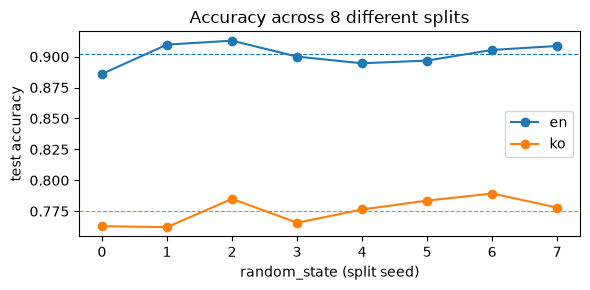

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
for col, color in [("en", "tab:blue"), ("ko", "tab:orange")]:
    ax.plot(seeds.index, seeds[col], "o-", color=color, label=col)
    ax.axhline(seeds[col].mean(), color=color, lw=0.8, ls="--")
ax.set_xlabel("random_state (split seed)")
ax.set_ylabel("test accuracy")
ax.set_title("Accuracy across 8 different splits")
ax.legend()
fig.tight_layout()
plt.show()

같은 모델, 같은 데이터인데도 분할만 바꾸면 정확도가 약 0.03 범위에서 오르내립니다. 그래서
- 리포트에는 시드 42의 점수를 보고하되, **"분할에 따라 ±0.01~0.02 정도 흔들린다"**는 사실을 함께 적습니다.
- 두 방법(예: 불용어 제거 전후)의 차이가 이 흔들림보다 작으면, "개선됐다"고 단정하지 않습니다.
- 시드를 바꿔 가며 가장 좋은 점수를 골라 보고하면 안 됩니다. 그것도 Test 정보를 이용한 일종의 누수입니다.

## 📝 리포트용 정리: 실험 설정

| 항목 | 설정 | 근거 |
|---|---|---|
| 분할 | Train/Test 8:2, `stratify=label`, `random_state=42` | 과제 요구. 주제 비율을 Train/Test에서 같게 유지 |
| TF-IDF | **Train 문서로만 fit**, Test는 transform만 | 누수 방지 (전체로 fit하면 정확도가 약간 올라감, 17.4) |
| 중복 | 분할 전에 제거 | Train 사본이 있는 Test 문서는 거의 다 맞혀 점수가 부풀려짐 |
| 점수 변동 | 시드 0~7의 평균·표준편차를 함께 보고 | 분할 운에 따라 약 0.03 범위로 흔들림 |

## ✍️ 실습: 분할과 벡터화 함수

`corpus`(text, label, tokens 열)와 `lang`, `seed`를 받아 `X_train, X_test, y_train, y_test, vec`를 돌려주는 `split_and_vectorize(corpus, lang, seed=42)`를 작성하세요.
- 8:2, `stratify`, `random_state=seed`
- `NumpyTfidf(min_df=MIN_DF[lang])`를 **Train으로만** fit
- 결과로 한국어 데이터의 각 shape과, Train에 없는 어휘가 Test 벡터에 들어가지 않았는지(`X_test.shape[1] == len(vec.vocabulary_)`) 확인

In [10]:
# 여기에 작성하세요

**정답**

In [11]:
def split_and_vectorize(corpus, lang, seed=RANDOM_STATE):
    train, test = train_test_split(corpus, test_size=0.2, stratify=corpus["label"], random_state=seed)
    vec = NumpyTfidf(min_df=MIN_DF[lang])
    X_train = vec.fit_transform(train["tokens"].tolist())
    X_test = vec.transform(test["tokens"].tolist())
    return X_train, X_test, train["label"].to_numpy(), test["label"].to_numpy(), vec


X_tr, X_te, y_tr, y_te, v = split_and_vectorize(ko, "ko")
print("X_train", X_tr.shape, "| X_test", X_te.shape, "| y_train", y_tr.shape, "| y_test", y_te.shape)
print("Test 벡터의 열 수 = Train 어휘 수:", X_te.shape[1] == len(v.vocabulary_))

X_train (5600, 5482) | X_test (1400, 5482) | y_train (5600,) | y_test (1400,)
Test 벡터의 열 수 = Train 어휘 수: True


이 함수에 모델 학습과 지표 계산을 붙인 것이 18~20장 첫 셀의 `run_classification`입니다.

In [12]:
# ── 17장에서 만든 분할·분류 코드 (src/classify.py로 옮길 내용) ──
from types import SimpleNamespace

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split


def split(corpus: pd.DataFrame, seed: int = RANDOM_STATE) -> tuple[pd.DataFrame, pd.DataFrame]:
    train, test = train_test_split(corpus, test_size=0.2, stratify=corpus["label"], random_state=seed)
    return train.reset_index(drop=True), test.reset_index(drop=True)


def run_classification(corpus: pd.DataFrame, lang: str, seed: int = RANDOM_STATE, C: float = 1.0):
    """Train으로만 TF-IDF를 fit하고, 로지스틱 회귀를 학습해 Test로 평가한다."""
    train, test = split(corpus, seed)
    vec = NumpyTfidf(min_df=MIN_DF[lang])
    X_train = vec.fit_transform(train["tokens"].tolist())
    X_test = vec.transform(test["tokens"].tolist())
    model = LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE).fit(X_train, train["label"])
    y_pred = model.predict(X_test)
    return SimpleNamespace(
        train=train, test=test, vec=vec, model=model, X_train=X_train, X_test=X_test,
        y_pred=y_pred, labels=list(model.classes_), proba=model.predict_proba(X_test),
        accuracy=accuracy_score(test["label"], y_pred),
        f1_macro=f1_score(test["label"], y_pred, average="macro"),
    )

res = run_classification(ko, "ko")
print(f"한국어 정확도 {res.accuracy:.3f}, macro F1 {res.f1_macro:.3f}")

한국어 정확도 0.770, macro F1 0.770


## 🧐 퀴즈

**Q1.** Train 정확도가 1.000인데 Test 정확도가 0.6이라면 어떤 상태이고, 무엇을 의심해야 하나요?
<details><summary>▶ 정답 보기</summary>

과적합입니다. 모델이 학습 문서에 지나치게 맞춰져 새 문서로 일반화하지 못합니다. 규제를 강하게 하거나(로지스틱 회귀의 `C`를 줄이기), 특성을 줄이거나, 데이터를 늘리는 방법을 검토합니다.
</details>

**Q2.** `stratify=corpus["label"]`을 빼면 어떤 문제가 생길 수 있나요?
<details><summary>▶ 정답 보기</summary>

Test의 카테고리 비율이 우연에 따라 전체와 달라집니다. 어떤 카테고리가 Test에 적게 들어가면 그 카테고리의 지표가 불안정해지고, 전체 점수도 분할 운에 더 크게 흔들립니다.
</details>

**Q3.** TF-IDF를 전체 데이터로 fit해도 정확도 차이가 작았습니다. 그런데도 Train으로만 fit해야 하는 이유는?
<details><summary>▶ 정답 보기</summary>

차이가 작아도 늘 실제보다 좋게 나오는 방향이라 보고한 점수를 믿을 수 없게 되고, 데이터 조건에 따라 차이가 커질 수 있으며, 실제 서비스에서는 미래 문서로 IDF를 계산할 수 없으므로 평가도 그 상황을 흉내 내야 하기 때문입니다.
</details>

**Q4.** 시드를 0~99까지 바꿔 보고 가장 높은 정확도를 리포트에 쓰면 왜 안 되나요?
<details><summary>▶ 정답 보기</summary>

Test 결과를 보고 설정을 고른 것이므로 Test 정보가 선택에 새어 들어간 셈입니다. 그 점수는 운이 좋은 분할의 점수일 뿐 일반화 성능이 아닙니다. 시드는 미리 정해 두고, 변동 폭은 평균과 표준편차로 함께 보고합니다.
</details>

## ✅ 체크포인트
- [ ] X와 y가 이 과제에서 각각 무엇이고 어떤 모양인지 말할 수 있다.
- [ ] Train 점수만으로 모델을 평가하면 안 되는 이유를 외우기 모델로 설명할 수 있다.
- [ ] `train_test_split`을 8:2, stratify, 시드 고정으로 쓸 수 있다.
- [ ] 두 가지 누수(전체 fit, 중복 문서)를 설명하고 막는 코드를 쓸 수 있다.
- [ ] 시드에 따른 점수 변동을 측정하고 리포트에 쓸 수 있다.

## 🔗 과제 연결과 다음 장
- `split`, `run_classification`은 `src/classify.py`가 됩니다. 실험 설정 표는 README의 분류 실험 부분에 씁니다.
- **18장. 선형 분류기**에서 로지스틱 회귀가 TF-IDF 벡터로 어떻게 점수를 매기고 확률을 만드는지 들여다봅니다.